# 02 · Modelagem Supervisionada — o aluno será alfabetizado?

Pipeline completa de Machine Learning (scikit-learn) para prever se um aluno do 2º ano será **alfabetizado** (proficiência Saeb ≥ 743),
usando **apenas informação disponível antes da prova**: contexto da escola e do município no ano anterior, metas, território e
socioeconomia.

**Protocolo (anti-leakage e generalização)**
1. Contexto de **2023** → resultado de **2024** (desenho temporal: é o cenário real de uso — prever o próximo ciclo).
2. Treino / validação / teste **agrupados por município** (nenhum município aparece em dois conjuntos).
3. Todo o pré-processamento (imputação, encoding, escala, engenharia de atributos) vive **dentro** do `Pipeline` → é ajustado só no treino de cada fold.
4. Comparação de modelos com **GroupKFold**; otimização com **RandomizedSearchCV** (CV agrupada).
5. Limiar de decisão escolhido na **validação**; o **teste** é usado uma única vez, no fim.

In [1]:
import sys, warnings, json
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import set_config

from src import config, main
from src.modeling import train
from src.modeling.pipelines import make_pipeline, MODEL_INPUT, ALL_NUMERIC
from src.preprocessing.features import TARGET, NUMERIC_FEATURES, CATEGORICAL_FEATURES, LEAKAGE_COLUMNS
from src.evaluation.metrics import classification_report_dict
from src.visualization import plots as vp

vp.set_style()
set_config(display="diagram")
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

## 1. Base de modelagem e verificação de vazamento

In [2]:
df = main.step_dataset()
print(f"{len(df):,} alunos presentes em 2024 · {df['id_municipio'].nunique():,} municípios · {df['id_escola'].nunique():,} escolas".replace(",", "."))

# Garantias explícitas contra data leakage
assert not set(LEAKAGE_COLUMNS) & set(df.columns), "variável pós-prova presente!"
assert all(c.endswith("_ant") or c in ("esc_n_matriculados",) or not c.startswith(("esc_", "mun_taxa", "mun_media", "mun_partic"))
           for c in NUMERIC_FEATURES), "contexto que não é do ano anterior"
grupos = {
    "Escola (2023)": [c for c in NUMERIC_FEATURES if c.startswith("esc_") and c.endswith("_ant")],
    "Escola (porte atual)": ["esc_n_matriculados"],
    "Município (2023)": [c for c in NUMERIC_FEATURES if c.startswith("mun_") and c.endswith("_ant")],
    "Metas (a priori)": ["mun_meta_ano_alvo", "uf_meta_ano_alvo"],
    "UF (2023)": ["uf_taxa_ant"],
    "Território / IBGE": ["capital", "dist_capital_km", "populacao_2019", "cresc_pop_2012_2019_pct", "pib_per_capita_2010", "latitude", "longitude"],
    "Categóricas": CATEGORICAL_FEATURES,
}
pd.DataFrame([(g, ", ".join(v)) for g, v in grupos.items()], columns=["grupo", "features"])

1.852.788 alunos presentes em 2024 · 5.517 municípios · 42.328 escolas


,grupo,features
0,Escola (2023),"esc_pct_alf_ant, esc_prof_media_ant, esc_taxa_..."
1,Escola (porte atual),esc_n_matriculados
2,Município (2023),"mun_taxa_rede_ant, mun_taxa_publica_ant, mun_m..."
3,Metas (a priori),"mun_meta_ano_alvo, uf_meta_ano_alvo"
4,UF (2023),uf_taxa_ant
5,Território / IBGE,"capital, dist_capital_km, populacao_2019, cres..."
6,Categóricas,"rede, sigla_uf, regiao, porte_municipio"


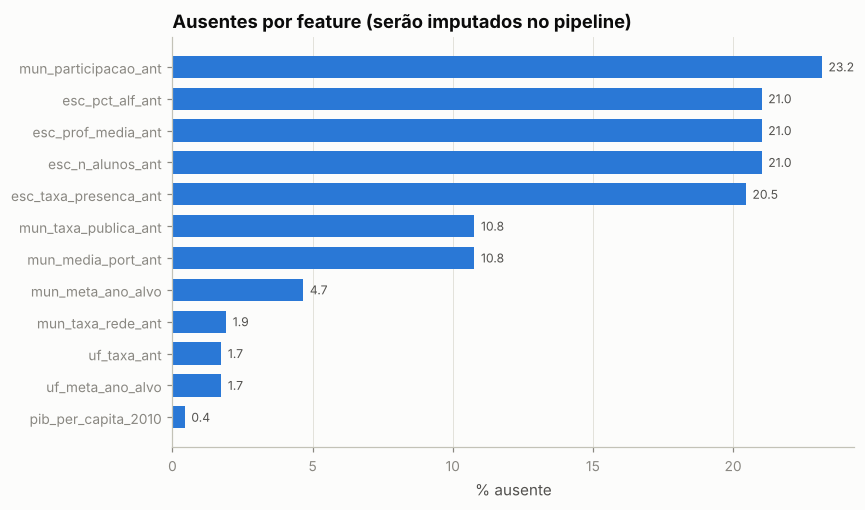

In [3]:
miss = df[MODEL_INPUT].isna().mean().sort_values(ascending=False)
ax = vp.barh(miss[miss > 0] * 100, "Ausentes por feature (serão imputados no pipeline)", "% ausente")
vp.save(ax.figure, "mod_ausentes"); plt.show()

Os ausentes têm causa conhecida: **SP, DF, AC e RR não têm microdados 2023** e escolas novas não têm histórico. Por isso a imputação
usa a **mediana do treino** e adiciona **indicadores de ausência** (`add_indicator=True`) — o modelo sabe que o dado foi imputado.

## 2. Separação treino / validação / teste (agrupada por município)

In [4]:
s = main.step_split(df)
display(s.summary())
print("Municípios em comum treino∩teste:", len(set(s.train.id_municipio) & set(s.test.id_municipio)))
print("Municípios em comum treino∩validação:", len(set(s.train.id_municipio) & set(s.val.id_municipio)))

,conjunto,alunos,municipios,escolas,taxa_alfabetizados
0,treino,1311776,3861,29872,0.5953
1,validação,297190,828,6616,0.6027
2,teste,243822,828,5840,0.6035


Municípios em comum treino∩teste: 0


Municípios em comum treino∩validação: 0


## 3. A pipeline (pré-processamento integrado ao modelo)

In [5]:
pipe_demo = make_pipeline("lightgbm")
pipe_demo

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('features', ...), ('preprocess', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{featur

In [6]:
# O que cada etapa produz (exemplo com 5 alunos do treino)
ex = s.train[MODEL_INPUT].head(5)
fe = pipe_demo.named_steps["features"].transform(ex)
print("Após FeatureEngineer:", fe.shape, "→ novas colunas:", [c for c in fe.columns if c not in ex.columns])
lin = make_pipeline("logistic").fit(s.train.sample(20_000, random_state=0)[MODEL_INPUT], s.train.sample(20_000, random_state=0)[TARGET])
Xt = lin[:-1].transform(ex)
print("Após ColumnTransformer (versão linear):", Xt.shape)
pd.DataFrame(Xt, columns=lin.named_steps["preprocess"].get_feature_names_out()).iloc[:, :12].round(2)

Após FeatureEngineer: (5, 29) → novas colunas: ['esc_vs_mun_ant', 'gap_meta_mun', 'esc_sem_historico', 'log_populacao', 'log_pib_per_capita', 'log_esc_n_matriculados']


Após ColumnTransformer (versão linear): (5, 77)


,esc_pct_alf_ant,esc_prof_media_ant,esc_taxa_presenca_ant,esc_n_alunos_ant,esc_n_matriculados,mun_taxa_rede_ant,mun_taxa_publica_ant,mun_media_port_ant,mun_participacao_ant,mun_meta_ano_alvo,uf_taxa_ant,uf_meta_ano_alvo
0,0.0500,-0.0300,0.1600,-0.2200,1.5700,-0.4000,-0.7600,-0.7400,0.0300,-1.1700,-0.4300,-0.3900
1,-0.0000,0.0500,0.3500,1.0200,0.5100,1.0100,1.0500,0.6000,0.0000,1.1700,0.8900,0.9400
2,1.2100,0.9000,-0.2900,-0.3600,0.0700,-0.4900,-0.7200,-0.6600,-2.1200,0.0200,0.6000,0.6200
3,-0.5600,-0.6100,0.3700,1.4900,-1.1700,0.5400,0.5700,1.2200,1.5800,0.6800,-0.0300,-0.0200
4,1.9800,1.8300,0.7100,-0.7900,-1.0500,1.9900,2.0900,2.8000,1.0200,1.7000,2.4700,2.1900


| Etapa | Numéricas | Categóricas |
|---|---|---|
| Engenharia de atributos (`FeatureEngineer`) | `esc_vs_mun_ant`, `gap_meta_mun`, `esc_sem_historico`, logs de população/PIB/matrícula | — |
| Imputação | mediana + indicador de ausência | moda |
| Transformação | `StandardScaler` (modelos lineares) | `OneHotEncoder` (lineares, `handle_unknown="ignore"`) · `OrdinalEncoder` (árvores) |
| Modelo | Logística · Random Forest · HistGradientBoosting · LightGBM | |

## 4. Comparação de algoritmos — validação cruzada agrupada (GroupKFold, 5 folds)

In [7]:
comp = main.step_compare(s, sample_n=200_000, n_splits=5)
comp

  baseline       AUC=0.5000 ± 0.0000


  logistic       AUC=0.6643 ± 0.0087


  random_forest  AUC=0.6650 ± 0.0084


  hist_gb        AUC=0.6610 ± 0.0093


  lightgbm       AUC=0.6605 ± 0.0089


,modelo,auc_cv_media,auc_cv_desvio,auc_treino,gap_overfitting,bal_acc_cv,brier_cv,tempo_s
0,random_forest,0.6650,0.0084,0.6976,0.0326,0.5972,0.2212,204.6314
1,logistic,0.6643,0.0087,0.6676,0.0033,0.5911,0.2217,37.1659
2,hist_gb,0.6610,0.0093,0.7223,0.0613,0.5960,0.2222,396.5136
3,lightgbm,0.6605,0.0089,0.7350,0.0745,0.5939,0.2224,89.2166
4,baseline,0.5000,0.0000,0.5000,0.0000,0.5000,0.2409,15.1969


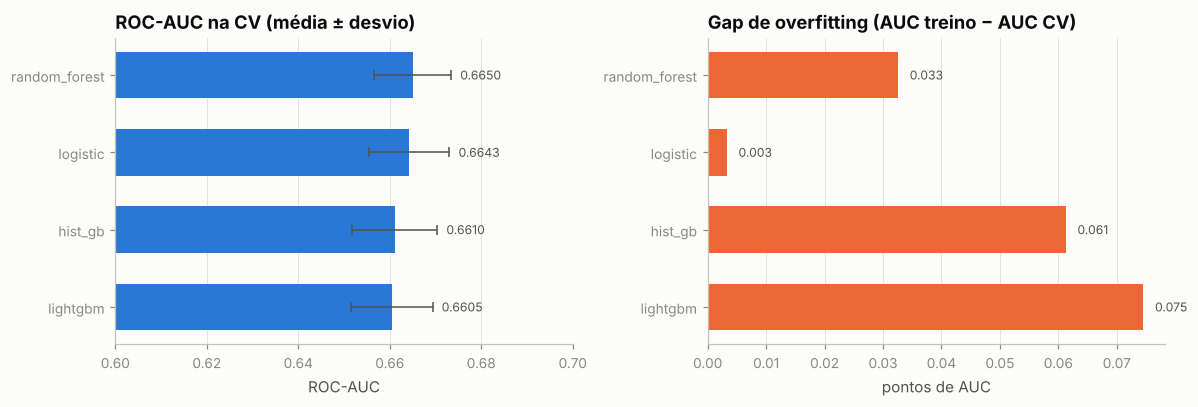

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
c = comp[comp.modelo != "baseline"].sort_values("auc_cv_media")
axes[0].barh(c.modelo, c.auc_cv_media, xerr=c.auc_cv_desvio, color=vp.CAT[0], height=0.6, capsize=3, error_kw=dict(ecolor=vp.INK2, lw=1))
axes[0].set_xlim(0.6, 0.7); axes[0].grid(axis="y", visible=False)
for i, (v, e) in enumerate(zip(c.auc_cv_media, c.auc_cv_desvio)): axes[0].text(v + e + 0.002, i, f"{v:.4f}", va="center", fontsize=8, color=vp.INK2)
axes[0].set(title="ROC-AUC na CV (média ± desvio)", xlabel="ROC-AUC")
axes[1].barh(c.modelo, c.gap_overfitting, color=vp.CAT[1], height=0.6)
for i, v in enumerate(c.gap_overfitting): axes[1].text(v + 0.002, i, f"{v:.3f}", va="center", fontsize=8, color=vp.INK2)
axes[1].set(title="Gap de overfitting (AUC treino − AUC CV)", xlabel="pontos de AUC"); axes[1].grid(axis="y", visible=False)
fig.tight_layout(); vp.save(fig, "mod_comparacao_cv"); plt.show()

**Leitura:** com hiperparâmetros padrão, os modelos ficam próximos em AUC, mas o **LightGBM sobreajusta** (maior gap treino−CV).
O teto de desempenho é limitado pela informação disponível (contexto, não o aluno), então o ganho virá de **regularização**: é o que a
otimização a seguir busca — o espaço inclui `min_child_samples`, `reg_lambda`, `reg_alpha`, `subsample` e `colsample_bytree`.

## 5. Otimização de hiperparâmetros (RandomizedSearchCV + GroupKFold)

In [9]:
best = main.step_tune(s, sample_n=300_000, n_iter=20)
tun = pd.read_csv(config.REPORTS_DIR / "tuning_lightgbm.csv")
print("Melhores hiperparâmetros:", json.dumps(best, indent=1))
tun.head(8)

Melhores hiperparâmetros: {
 "colsample_bytree": 0.8856351733429728,
 "learning_rate": 0.02321793559503287,
 "min_child_samples": 280,
 "n_estimators": 240,
 "num_leaves": 42,
 "reg_alpha": 2.8340904295147746,
 "reg_lambda": 3.499331111708852,
 "subsample": 0.7323592099410596
}


,param_model__colsample_bytree,param_model__learning_rate,param_model__min_child_samples,param_model__n_estimators,param_model__num_leaves,param_model__reg_alpha,param_model__reg_lambda,param_model__subsample,mean_test_score,std_test_score,mean_train_score,rank_test_score
0,0.8856,0.0232,280,240,42,2.8341,3.4993,0.7324,0.6657,0.0094,0.6903,1
1,0.7962,0.0220,868,220,87,0.0018,22.4132,0.9863,0.6651,0.0088,0.6973,2
2,0.7296,0.0392,921,330,36,0.0017,6.1444,0.9754,0.6650,0.0091,0.6991,3
3,0.7839,0.0213,451,755,48,0.0381,19.7445,0.8909,0.6646,0.0091,0.7119,4
4,0.5318,0.0374,777,298,58,0.3550,15.7664,0.7889,0.6645,0.0092,0.7053,5
5,0.8059,0.0265,525,389,76,1.3826,0.3123,0.8057,0.6641,0.0089,0.7140,6
6,0.8238,0.0200,794,458,117,0.0046,2.1038,0.7939,0.6632,0.0090,0.7195,7
7,0.8462,0.0344,713,573,46,0.1189,5.5140,0.7455,0.6632,0.0090,0.7155,8


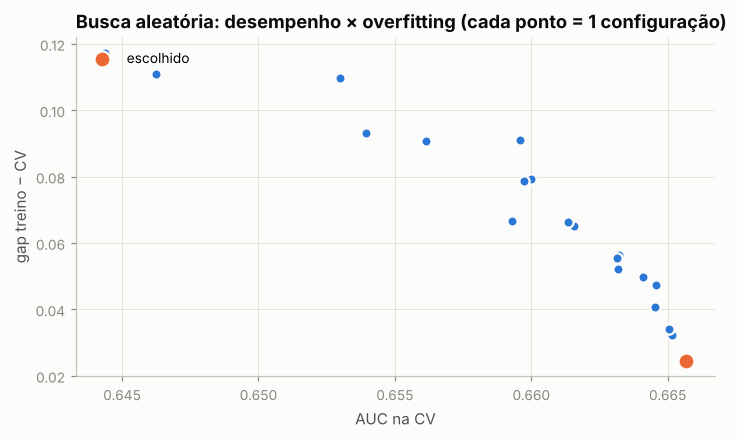

In [10]:
fig, ax = plt.subplots(figsize=(7.5, 4))
ax.scatter(tun["mean_test_score"], tun["mean_train_score"] - tun["mean_test_score"], s=45, color=vp.CAT[0], edgecolors=vp.SURFACE, linewidths=1.5)
b = tun.iloc[0]
ax.scatter([b.mean_test_score], [b.mean_train_score - b.mean_test_score], s=110, color=vp.CAT[1], edgecolors=vp.SURFACE, linewidths=1.5, label="escolhido")
ax.set(title="Busca aleatória: desempenho × overfitting (cada ponto = 1 configuração)", xlabel="AUC na CV", ylabel="gap treino − CV")
ax.legend(loc="upper left"); vp.save(fig, "mod_tuning"); plt.show()

## 6. Treino final, limiar e avaliação no conjunto de teste

In [11]:
out = main.step_final(s, best)
tab = pd.DataFrame({k: out[k] for k in ["treino", "validacao", "teste"]}).T
tab[["roc_auc", "pr_auc", "balanced_accuracy", "f1_macro", "recall_nao_alfabetizado", "precision_nao_alfabetizado", "f1", "brier", "n"]]

,roc_auc,pr_auc,balanced_accuracy,f1_macro,recall_nao_alfabetizado,precision_nao_alfabetizado,f1,brier,n
treino,0.6805,0.7561,0.6211,0.6225,0.5030,0.5673,0.7117,0.2177,"1,311,776.0000"
validacao,0.6389,0.7268,0.5899,0.5901,0.4217,0.5346,0.7087,0.2249,"297,190.0000"
teste,0.6647,0.7540,0.6074,0.6083,0.4998,0.5353,0.6997,0.2197,"243,822.0000"


In [12]:
print(f"Limiar escolhido na validação (máx. F1-macro): {out['threshold']:.2f}")
print(f"Gap treino−teste (AUC): {out['treino']['roc_auc'] - out['teste']['roc_auc']:.4f}  → generalização estável")
cmp = pd.DataFrame({"LightGBM otimizado": out["teste"], "Regressão logística": out["teste_logistic"]}).T
cmp[["roc_auc", "pr_auc", "balanced_accuracy", "brier", "log_loss"]]

Limiar escolhido na validação (máx. F1-macro): 0.54
Gap treino−teste (AUC): 0.0158  → generalização estável


,roc_auc,pr_auc,balanced_accuracy,brier,log_loss
LightGBM otimizado,0.6647,0.7540,0.6074,0.2197,0.6272
Regressão logística,0.6615,0.7511,0.5915,0.2209,0.6302


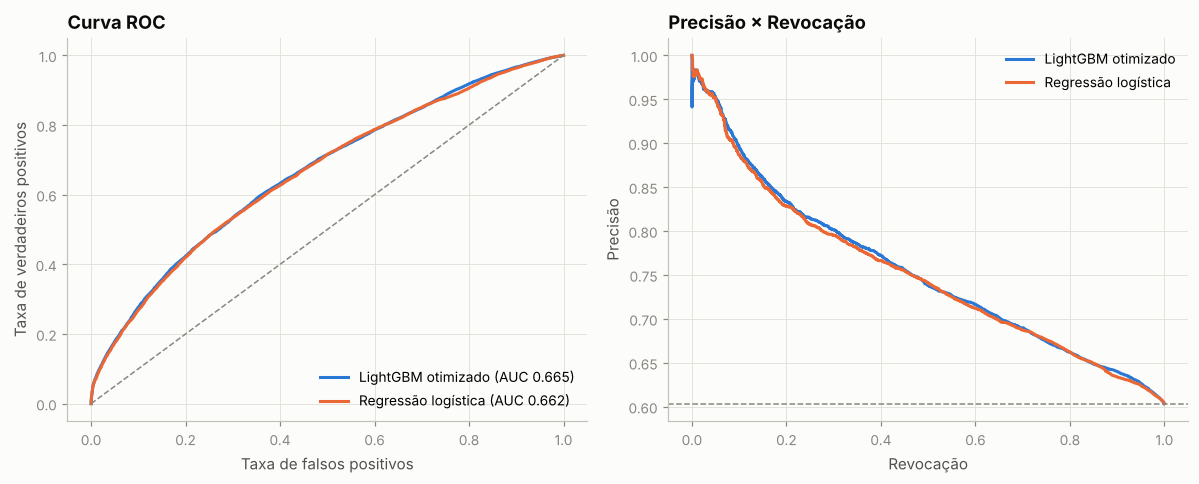

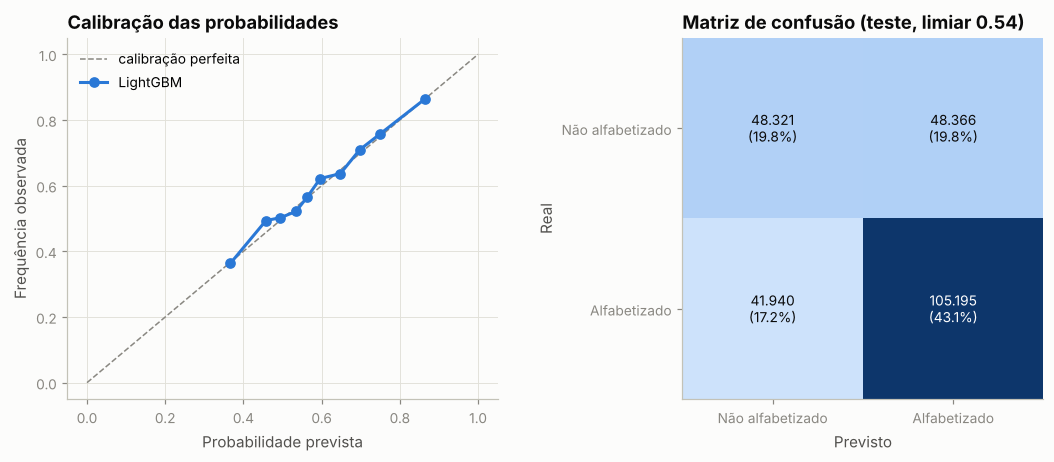

In [13]:
pipe = train.load_model("modelo_alfabetizacao_lgbm")
logit = train.load_model("modelo_alfabetizacao_logistic")
p_lgb = train.predict_proba(pipe, s.test)
p_log = train.predict_proba(logit, s.test)
fig = vp.roc_pr_curves({"LightGBM otimizado": p_lgb, "Regressão logística": p_log}, s.test[TARGET].values)
vp.save(fig, "mod_roc_pr"); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(10, 4.3))
vp.calibration_plot(s.test[TARGET], p_lgb, ax=axes[0], label="LightGBM")
t = out["teste"]
vp.confusion_plot(t["tn"], t["fp"], t["fn"], t["tp"], ax=axes[1], title=f"Matriz de confusão (teste, limiar {out['threshold']:.2f})")
fig.tight_layout(); vp.save(fig, "mod_calibracao_confusao"); plt.show()

## 7. Robustez — desempenho por subgrupo e estabilidade (replicabilidade)

In [14]:
reg = pd.read_csv(config.REPORTS_DIR / "metricas_por_regiao.csv")
rede = pd.read_csv(config.REPORTS_DIR / "metricas_por_rede.csv")
display(reg.round(3)); display(rede.round(3))

,regiao,n,taxa_real,taxa_prevista,roc_auc,balanced_accuracy,recall_nao_alfabetizado
0,Centro-Oeste,16073,0.7110,0.6690,0.6000,0.5390,0.1450
1,Nordeste,65696,0.5980,0.5880,0.7290,0.6610,0.6460
2,Norte,41761,0.5110,0.4860,0.5800,0.5400,0.8050
3,Sudeste,86228,0.6190,0.6310,0.6280,0.5650,0.3160
4,Sul,34064,0.6380,0.6330,0.6520,0.5820,0.3050


,rede,n,taxa_real,taxa_prevista,roc_auc,balanced_accuracy,recall_nao_alfabetizado
0,Estadual,24803,0.6270,0.6240,0.6130,0.5350,0.1790
1,Municipal,219019,0.6010,0.5940,0.6690,0.6140,0.5340


In [15]:
# Replicabilidade: mesmo pipeline, 3 sementes diferentes (amostra de 300 mil alunos do treino)
rows = []
for seed in (7, 42, 2024):
    amostra = s.train.sample(300_000, random_state=seed)
    p = make_pipeline("lightgbm", **{**best, "random_state": seed}).fit(amostra[MODEL_INPUT], amostra[TARGET])
    pr = p.predict_proba(s.test[MODEL_INPUT])[:, 1]
    m = classification_report_dict(s.test[TARGET], pr, out["threshold"])
    rows.append({"semente": seed, "roc_auc_teste": m["roc_auc"], "balanced_accuracy": m["balanced_accuracy"], "brier": m["brier"]})
estab = pd.DataFrame(rows)
display(estab)
print(f"Desvio-padrão da AUC entre sementes: {estab.roc_auc_teste.std():.4f}")

,semente,roc_auc_teste,balanced_accuracy,brier
0,7,0.6646,0.6072,0.2197
1,42,0.6638,0.6048,0.2198
2,2024,0.6647,0.6099,0.2198


Desvio-padrão da AUC entre sementes: 0.0005


## 8. Conclusões da modelagem

*(números completos em `reports/metricas.json`)*

| Conjunto | ROC-AUC | PR-AUC | Acurácia balanceada | Recall "não alfabetizado" | Brier |
|---|---|---|---|---|---|
| Treino | 0.680 | 0.756 | 0.621 | 0.503 | 0.218 |
| Validação | 0.639 | 0.727 | 0.590 | 0.422 | 0.225 |
| **Teste** | **0.665** | **0.754** | **0.607** | **0.500** | **0.220** |
| Teste — logística | 0.662 | 0.751 | 0.592 | 0.390 | 0.221 |

* **Algoritmo escolhido: LightGBM regularizado.** A otimização inverteu o quadro da CV inicial: com `min_child_samples` alto, `reg_alpha`/`reg_lambda`
  e taxa de aprendizado baixa, o gap de overfitting caiu de ≈ 0,075 para ≈ 0,025 e a AUC na CV subiu para ≈ 0,666. A vantagem sobre a
  regressão logística é **pequena** (≈ +0,003 de AUC e +0,016 de acurácia balanceada, com recall de "não alfabetizado" bem maior no limiar
  escolhido) — a relação é majoritariamente monotônica, e a logística segue como *baseline* interpretável.
* **Generalização:** gap treino−teste ≈ 0,016 de AUC; desvio entre sementes ≈ 0,0005; desvio entre folds < 0,01 → resultado estável e replicável.
  A validação (828 municípios distintos) ficou um pouco abaixo do teste — variação natural entre grupos de municípios, reportada sem ajuste.
* **Calibração:** as probabilidades seguem a diagonal, o que permite **somá-las** para estimar a taxa esperada de uma escola ou município (notebook 03).
* **Equidade:** o desempenho varia por região (AUC maior no Nordeste, menor no Norte e no Centro-Oeste) — informação importante para o uso responsável.
* **Limite honesto:** ROC-AUC ≈ 0,66 no nível do aluno. O resultado individual depende de fatores ausentes nas bases públicas (família,
  frequência, professor, prática de leitura). O modelo **não deve rotular crianças**; seu uso correto é **priorizar territórios e escolas**,
  onde a agregação das probabilidades é muito mais precisa.